# Train the context-aware chord-refinement Transformer

This notebook **performs training**, using the existing manual PyTorch architecture and immutable v6 multi-bar dataset. The training loop is here in the notebook; it does not call a training `.py` script.

One token is one beat. Predictions are detailed reference-chord classes. We use exactly the requested 17 input tensors and two target tensors. `target_loss_mask` is a supervision mask, not a second prediction head.

Run all cells in order with the repository `.venv` kernel. CPU is supported. Each Run All creates a new protected output directory, leaving previous runs and all dataset snapshots intact. Defaults: 10 epochs maximum, batch 32, learning rate 0.001, early-stopping patience 3. These were approved for this first experiment.

## 1. Imports and repository location

We import the existing model, loss, checkpoint functions and numerical dataset loader. No architecture is duplicated inside the notebook.

In [1]:
from pathlib import Path
import sys
root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'experiments/rahul/src').is_dir()), None)
if root is None:
    raise RuntimeError('Run this notebook from within the vocal-harmonization repository')
if str(root) not in sys.path:
    sys.path.insert(0,str(root))
import bisect
from dataclasses import asdict
from datetime import datetime, timedelta, timezone
import hashlib
import json
import random
import time
import numpy as np
import torch
from torch.utils.data import Dataset
import matplotlib.pyplot as plt
from IPython.display import display
from experiments.rahul.src.model import DatasetSpec, ModelConfig, ChordRefinementTransformer, masked_cross_entropy
from experiments.rahul.src.model.checkpoint import save_checkpoint, load_checkpoint
from experiments.rahul.src.transformer_dataset import SavedSequenceDataset, make_dataloader, collate_sequences
print('PyTorch:',torch.__version__,'CUDA available:',torch.cuda.is_available())

Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\srjay\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


PyTorch: 2.14.1+cpu CUDA available: False


## 2. Exact input and target columns

The saved NPZ/CSV prefixes are removed by `SavedSequenceDataset`. Only the keys below are forwarded. Source IDs, extra melody representations, neighboring chords and reference audit labels are excluded.

In [2]:
INPUT_KEYS = (
    'basic_chord_ids', 'melody_pitch_ids', 'melody_timing', 'melody_note_mask',
    'melody_silent', 'key_ids', 'mode_ids', 'roman_ids', 'harmonic_function_ids',
    'genre_features', 'beat_index', 'bar_number', 'beat_position', 'event_duration',
    'relative_bar_number', 'beat_timing_known_mask', 'beat_attention_mask',
)
TARGET_KEYS = ('target_chord_ids','target_loss_mask')
assert len(INPUT_KEYS)==17
print('Inputs:'); print('\n'.join('inputs__'+k for k in INPUT_KEYS))
print('Targets:'); print('\n'.join('targets__'+k for k in TARGET_KEYS))

Inputs:
inputs__basic_chord_ids
inputs__melody_pitch_ids
inputs__melody_timing
inputs__melody_note_mask
inputs__melody_silent
inputs__key_ids
inputs__mode_ids
inputs__roman_ids
inputs__harmonic_function_ids
inputs__genre_features
inputs__beat_index
inputs__bar_number
inputs__beat_position
inputs__event_duration
inputs__relative_bar_number
inputs__beat_timing_known_mask
inputs__beat_attention_mask
Targets:
targets__target_chord_ids
targets__target_loss_mask


## 3. Reproducible settings

CPU is selected for this Windows machine. Change DEVICE to CUDA only with an available CUDA-enabled PyTorch installation. Seeded shuffling and fixed settings support repeatable runs on the same software/hardware; cross-device bitwise equality is not promised.

In [3]:
SEED = 42
MAX_EPOCHS = 10
BATCH_SIZE = 32
LEARNING_RATE = 0.001
PATIENCE = 3
THREADS = 4
DEVICE = torch.device('cpu')
DATASET_DIR = root/'experiments/rahul/outputs/model_preprocessing/final_all_tracks_quality_v6_multibar'
run_stamp = datetime.now(timezone(timedelta(hours=5,minutes=30))).strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR = root/'experiments/rahul/outputs/transformer_training'/('notebook_full_inputs_'+run_stamp)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(THREADS)
if DEVICE.type=='cuda':
    if not torch.cuda.is_available(): raise RuntimeError('CUDA is unavailable')
    torch.cuda.manual_seed_all(SEED)
print('Device:',DEVICE,'Run folder:',RUN_DIR)

Device: cpu Run folder: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization\experiments\rahul\outputs\transformer_training\notebook_full_inputs_20261019_194104_127905


## 4. Data helpers and numerical shard caching

Shuffling across tracks would otherwise decompress the same shards repeatedly. This wrapper reuses `SavedSequenceDataset` and caches its numerical arrays in RAM, discarding unused arrays **only in memory**. It preserves the original loader and dynamic collation. Test data are not scored or loaded here.

`select_batch` enforces the exact model input/target contract.

In [4]:
def select_batch(batch, device):
    return ({key:batch['inputs'][key].to(device) for key in INPUT_KEYS},
            {key:batch['targets'][key].to(device) for key in TARGET_KEYS})

class CachedSelectedDataset(Dataset):
    def __init__(self, index_path):
        original = SavedSequenceDataset(index_path)
        if original._shards is None:
            self.shards, self.ends = [original], [len(original)]
        else:
            self.shards = [SavedSequenceDataset(p) for p in original._shards]
            self.ends = list(original._ends)
        keep = {'inputs__'+k for k in INPUT_KEYS} | {'targets__'+k for k in TARGET_KEYS}
        for shard in self.shards:
            shard.arrays = {k:v for k,v in shard.arrays.items()
                            if not k.startswith(('inputs__','targets__')) or k in keep}
    def __len__(self):
        return self.ends[-1]
    def __getitem__(self,index):
        if index<0: index+=len(self)
        if not 0<=index<len(self): raise IndexError(index)
        shard = bisect.bisect_right(self.ends,index)
        local = index-(self.ends[shard-1] if shard else 0)
        item = self.shards[shard][local]
        item['metadata']['sequence_index']=index
        return item

def atomic_json(path, value):
    path=Path(path)
    temporary=path.with_suffix(path.suffix+'.tmp')
    temporary.write_text(json.dumps(value,indent=2,allow_nan=False)+'\n',encoding='utf-8')
    temporary.replace(path)

def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()

## 5. Load training and validation splits; check actual shapes

Each training epoch visits every saved training sequence. No new split, vocabulary or target is generated. The saved indices determine the counts and track membership. The first batch inspection does not consume the shuffled training loader's RNG.

In [5]:
indices = {split:json.loads((DATASET_DIR/f'{split}_sequences.json').read_text())
           for split in ('train','validation','test')}
track_files = {split:{Path(s['path']).name for s in index['shards']} for split,index in indices.items()}
assert not (track_files['train'] & track_files['validation'])
assert not (track_files['train'] & track_files['test'])
assert not (track_files['validation'] & track_files['test'])
train_data = CachedSelectedDataset(DATASET_DIR/'train_sequences.json')
validation_data = CachedSelectedDataset(DATASET_DIR/'validation_sequences.json')
train_loader = make_dataloader(train_data,batch_size=BATCH_SIZE,shuffle=True,seed=SEED)
validation_loader = make_dataloader(validation_data,batch_size=BATCH_SIZE,shuffle=False,seed=SEED)
example_batch = collate_sequences([train_data[i] for i in range(min(4,len(train_data)))])
example_inputs, example_targets = select_batch(example_batch,DEVICE)
assert set(example_inputs)==set(INPUT_KEYS) and set(example_targets)==set(TARGET_KEYS)
display({split:{'tracks':len(index['shards']),'sequences':index['sequences'],'real_beats':index['real_beats']}
         for split,index in indices.items()})
display({k:{'shape':list(v.shape),'dtype':str(v.dtype)} for k,v in example_inputs.items()})

{'train': {'tracks': 470, 'sequences': 12718, 'real_beats': 186572},
 'validation': {'tracks': 23, 'sequences': 814, 'real_beats': 11319},
 'test': {'tracks': 32, 'sequences': 990, 'real_beats': 14278}}

{'basic_chord_ids': {'shape': [4, 16], 'dtype': 'torch.int64'},
 'melody_pitch_ids': {'shape': [4, 16, 32], 'dtype': 'torch.int64'},
 'melody_timing': {'shape': [4, 16, 32, 3], 'dtype': 'torch.float32'},
 'melody_note_mask': {'shape': [4, 16, 32], 'dtype': 'torch.bool'},
 'melody_silent': {'shape': [4, 16], 'dtype': 'torch.bool'},
 'key_ids': {'shape': [4, 16], 'dtype': 'torch.int64'},
 'mode_ids': {'shape': [4, 16], 'dtype': 'torch.int64'},
 'roman_ids': {'shape': [4, 16], 'dtype': 'torch.int64'},
 'harmonic_function_ids': {'shape': [4, 16], 'dtype': 'torch.int64'},
 'genre_features': {'shape': [4, 63], 'dtype': 'torch.float32'},
 'beat_index': {'shape': [4, 16], 'dtype': 'torch.float32'},
 'bar_number': {'shape': [4, 16], 'dtype': 'torch.float32'},
 'beat_position': {'shape': [4, 16], 'dtype': 'torch.float32'},
 'event_duration': {'shape': [4, 16], 'dtype': 'torch.float32'},
 'relative_bar_number': {'shape': [4, 16], 'dtype': 'torch.float32'},
 'beat_timing_known_mask': {'shape': [4,

## 6. Initialize the existing architecture with all requested timing features

The original architecture accepts relative bar/beat timing. The backwards-compatible `use_absolute_timing=True` option also consumes absolute beat index and source bar number.

The temporal projection receives seven numerical features: log1p(beat position), log1p(relative bar), log1p(duration), bar-known, position-known, log1p(beat index), log1p(absolute bar). Unknown bar/position placeholders are masked before projection. These are not categorical embedding indices.

Other architecture defaults remain: 128 model dimensions, 4 heads, 2 pre-norm bidirectional layers, 256 feed-forward width, dropout 0.1. Melody pooling uses real-note masks, not dummy silence attention slots. PAD/ambiguous targets do not contribute to loss; ambiguous real beats remain attention context.

In [6]:
spec = DatasetSpec.from_folder(DATASET_DIR)
model_config = ModelConfig(use_absolute_timing=True)
model = ChordRefinementTransformer(spec,model_config).to(DEVICE)
model.eval()
with torch.no_grad():
    example_logits = model(example_inputs)
assert example_logits.shape[:2]==example_inputs['beat_attention_mask'].shape
assert example_logits.shape[-1]==spec.num_target_classes
assert torch.isfinite(example_logits).all()
print('Parameters:',sum(p.numel() for p in model.parameters()))
print('Output:',tuple(example_logits.shape),'Target classes:',spec.num_target_classes)
print('Temporal projection inputs:',model.encoders['genre_temporal'].temporal.in_features)

Parameters: 349074
Output: (4, 16, 402) Target classes: 402
Temporal projection inputs: 7


## 7. Define one training/evaluation epoch

Cross-entropy and exact detailed-class accuracy are weighted by the number of valid real targets, not averaged equally across differently sized batches. `target_loss_mask & beat_attention_mask` selects supervision. Ignored targets use -100.

Training enables dropout and updates weights; validation disables dropout and gradients. Gradients are clipped to norm 1 and checked for non-finite values. All positions are dynamically padded by the existing loader.

In [7]:
def run_epoch(model, loader, device, optimizer=None, label='', log_every=100):
    training = optimizer is not None
    model.train(training)
    total_loss = correct = valid_count = real_beats = sequences = steps = 0
    started = time.perf_counter()
    with torch.set_grad_enabled(training):
        for number,batch in enumerate(loader,1):
            inputs,targets = select_batch(batch,device)
            active = targets['target_loss_mask'] & inputs['beat_attention_mask']
            count = int(active.sum())
            if training: optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = masked_cross_entropy(logits,targets,inputs['beat_attention_mask'])
            if not torch.isfinite(loss) or not torch.isfinite(logits).all():
                raise FloatingPointError(f'Non-finite loss/logits in {label}, batch {number}')
            if training and count:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),1.0,error_if_nonfinite=True)
                optimizer.step()
                steps += 1
            total_loss += float(loss.detach())*count
            correct += int((logits.detach().argmax(-1)[active]==targets['target_chord_ids'][active]).sum())
            valid_count += count
            real_beats += int(inputs['beat_attention_mask'].sum())
            sequences += len(inputs['beat_attention_mask'])
            if log_every and (number==1 or number%log_every==0):
                print(f'{label} batch {number}/{len(loader)} loss={total_loss/max(1,valid_count):.5f} '
                      f'accuracy={correct/max(1,valid_count):.2%}',flush=True)
    if not valid_count: raise ValueError('No valid supervision in split')
    return {'loss':total_loss/valid_count,'accuracy':correct/valid_count,
            'correct_targets':correct,'valid_targets':valid_count,'real_beats':real_beats,
            'sequences':sequences,'optimizer_steps':steps,'seconds':time.perf_counter()-started}

## 8. Record configuration and random-initialization validation

Create a fresh run directory and record saved vocabulary/index identities. AdamW uses weight decay 0.01. ReduceLROnPlateau halves the learning rate after its patience of one. The test split does not influence learning rate, early stopping or checkpoint selection.

In [8]:
RUN_DIR.mkdir(parents=True,exist_ok=False)
protected_names = ('feature_vocabularies.json','target_vocabulary.json',
                   'train_sequences.json','validation_sequences.json','test_sequences.json')
hashes_before = {name:sha256_file(DATASET_DIR/name) for name in protected_names}
training_config = {'dataset':str(DATASET_DIR),'run_dir':str(RUN_DIR),'seed':SEED,
    'max_epochs':MAX_EPOCHS,'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE,
    'patience':PATIENCE,'device':str(DEVICE),'threads':THREADS,
    'input_columns':['inputs__'+k for k in INPUT_KEYS],
    'target_columns':['targets__'+k for k in TARGET_KEYS],
    'model':asdict(model_config),'spec':asdict(spec),
    'parameters':sum(p.numel() for p in model.parameters()),
    'optimizer':'AdamW','weight_decay':0.01,'clip_norm':1.0,
    'scheduler':'ReduceLROnPlateau(factor=0.5,patience=1)',
    'torch_version':str(torch.__version__),'dataset_hashes_before':hashes_before}
atomic_json(RUN_DIR/'training_config.json',training_config)
optimizer = torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,factor=0.5,patience=1)
initial_validation = run_epoch(model,validation_loader,DEVICE,label='Initial validation',log_every=0)
atomic_json(RUN_DIR/'initial_validation.json',initial_validation)
atomic_json(RUN_DIR/'status.json',{'status':'ready_to_train'})
display(initial_validation)

{'loss': 6.053405601880077,
 'accuracy': 0.01141430354913501,
 'correct_targets': 128,
 'valid_targets': 11214,
 'real_beats': 11319,
 'sequences': 814,
 'optimizer_steps': 0,
 'seconds': 1.2037196999990556}

## 9. Train, validate and save the best checkpoint

This cell performs the full training loop. Selection uses **minimum validation cross-entropy**, not test accuracy. Stop after three consecutive non-improving epochs. All epochs use the entire training split. Existing checkpoints in other run directories are untouched.

Stop the kernel/cell to interrupt. Completed history and the last epoch's model/optimizer/scheduler/RNG state remain on disk; this notebook does not implement automatic resume. Running this training cell twice for the same run is rejected to prevent accidental extra training.

In [9]:
if (RUN_DIR/'history.json').exists():
    raise RuntimeError('This run has training history. Run All to create a fresh run directory.')
history = []
best_loss, best_epoch, stale = float('inf'), 0, 0
training_started = time.perf_counter()
try:
    for epoch in range(1,MAX_EPOCHS+1):
        atomic_json(RUN_DIR/'status.json',{'status':'training','epoch':epoch,'max_epochs':MAX_EPOCHS})
        current_lr = optimizer.param_groups[0]['lr']
        train_metrics = run_epoch(model,train_loader,DEVICE,optimizer,label=f'Epoch {epoch} train')
        validation_metrics = run_epoch(model,validation_loader,DEVICE,label=f'Epoch {epoch} validation',log_every=0)
        assert train_metrics['sequences']==indices['train']['sequences']
        assert train_metrics['real_beats']==indices['train']['real_beats']
        assert validation_metrics['sequences']==indices['validation']['sequences']
        scheduler.step(validation_metrics['loss'])
        improved = validation_metrics['loss']<best_loss
        if improved:
            best_loss,best_epoch,stale = validation_metrics['loss'],epoch,0
            save_checkpoint(RUN_DIR/'best.pt.tmp',model)
            (RUN_DIR/'best.pt.tmp').replace(RUN_DIR/'best.pt')
        else:
            stale += 1
        history.append({'epoch':epoch,'learning_rate':current_lr,'train':train_metrics,
                        'validation':validation_metrics,'saved_best':improved})
        atomic_json(RUN_DIR/'history.json',history)
        torch.save({'epoch':epoch,'model_config':asdict(model_config),'spec':asdict(spec),
                    'model_state_dict':model.state_dict(),'optimizer_state_dict':optimizer.state_dict(),
                    'scheduler_state_dict':scheduler.state_dict(),'best_epoch':best_epoch,
                    'best_validation_loss':best_loss,'rng_state':torch.get_rng_state(),
                    'shuffle_rng_state':train_loader.generator.get_state()},RUN_DIR/'last_training_state.pt.tmp')
        (RUN_DIR/'last_training_state.pt.tmp').replace(RUN_DIR/'last_training_state.pt')
        print(f'Epoch {epoch}: train loss {train_metrics["loss"]:.5f}, '
              f'validation loss {validation_metrics["loss"]:.5f}, '
              f'validation accuracy {validation_metrics["accuracy"]:.2%}; best epoch {best_epoch}',flush=True)
        if stale>=PATIENCE:
            print('Early stopping: validation loss did not improve.',flush=True)
            break
    atomic_json(RUN_DIR/'status.json',{'status':'trained_pending_evaluation',
                                     'completed_epochs':len(history),'best_epoch':best_epoch})
except BaseException as exc:
    atomic_json(RUN_DIR/'status.json',{'status':'interrupted' if isinstance(exc,KeyboardInterrupt) else 'failed',
                                     'error':repr(exc),'completed_epochs':len(history)})
    raise
print('Training seconds:',round(time.perf_counter()-training_started,2))

Epoch 1 train batch 1/398 loss=6.30764 accuracy=0.22%


Epoch 1 train batch 100/398 loss=1.72480 accuracy=71.79%


Epoch 1 train batch 200/398 loss=1.19694 accuracy=78.16%


Epoch 1 train batch 300/398 loss=0.99580 accuracy=80.57%


Epoch 1: train loss 0.88381, validation loss 0.58613, validation accuracy 86.58%; best epoch 1


...

Epoch 4 train batch 200/398 loss=0.31469 accuracy=91.00%


Epoch 4 train batch 300/398 loss=0.30979 accuracy=91.21%


Epoch 4: train loss 0.30553, validation loss 0.60362, validation accuracy 85.12%; best epoch 1


Early stopping: validation loss did not improve.


Training seconds: 250.8


## 10. Learning curves

Training scores were gathered while weights changed and dropout was enabled. Validation scores use eval mode, so the two curves have different measurement conditions.

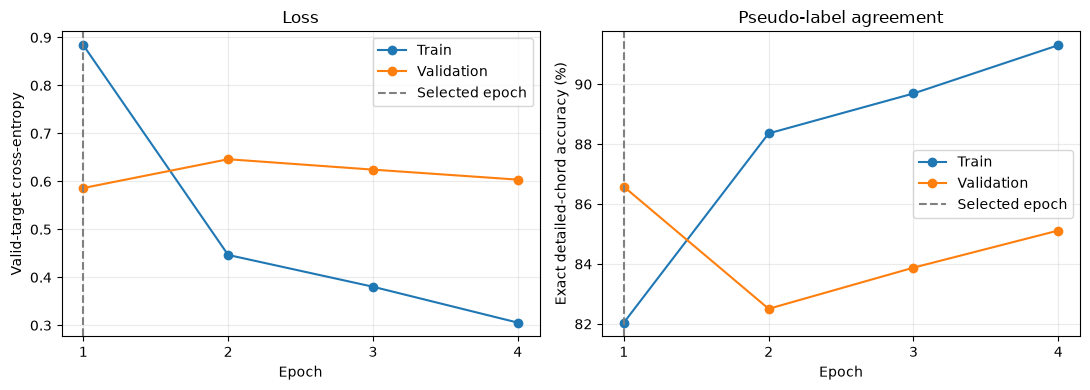

In [10]:
epochs = [row['epoch'] for row in history]
fig,axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(epochs,[row['train']['loss'] for row in history],marker='o',label='Train')
axes[0].plot(epochs,[row['validation']['loss'] for row in history],marker='o',label='Validation')
axes[0].set(ylabel='Valid-target cross-entropy',xlabel='Epoch',title='Loss')
axes[1].plot(epochs,[100*row['train']['accuracy'] for row in history],marker='o',label='Train')
axes[1].plot(epochs,[100*row['validation']['accuracy'] for row in history],marker='o',label='Validation')
axes[1].set(ylabel='Exact detailed-chord accuracy (%)',xlabel='Epoch',title='Pseudo-label agreement')
for ax in axes:
    ax.axvline(best_epoch,color='gray',linestyle='--',label='Selected epoch')
    ax.set_xticks(epochs); ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RUN_DIR/'learning_curves.png',dpi=160)
plt.show()

## 11. Restore the selected checkpoint and evaluate the held-out test split

Only now do we load the test dataset. The selected model is restored before evaluation. Accuracy is the fraction of valid real beats whose predicted detailed class exactly matches the reference, including legitimate N labels. No padding or ambiguous targets enter the denominator.

In [11]:
best_model = load_checkpoint(RUN_DIR/'best.pt',DATASET_DIR,DEVICE)
best_validation = run_epoch(best_model,validation_loader,DEVICE,label='Best validation',log_every=0)
test_data = CachedSelectedDataset(DATASET_DIR/'test_sequences.json')
test_loader = make_dataloader(test_data,batch_size=BATCH_SIZE,shuffle=False,seed=SEED)
test_metrics = run_epoch(best_model,test_loader,DEVICE,label='Held-out test',log_every=0)
assert test_metrics['sequences']==indices['test']['sequences']
assert test_metrics['real_beats']==indices['test']['real_beats']
results = {'status':'complete','completed_epochs':len(history),'best_epoch':best_epoch,
    'early_stopped':len(history)<MAX_EPOCHS,'initial_validation':initial_validation,
    'best_validation':best_validation,'test':test_metrics,
    'parameters':sum(p.numel() for p in best_model.parameters()),
    'best_checkpoint':str(RUN_DIR/'best.pt'),'best_checkpoint_sha256':sha256_file(RUN_DIR/'best.pt'),
    'training_and_evaluation_seconds':time.perf_counter()-training_started,
    'limitations':'Automatic reference pseudo-labels and synthetic reference-derived basic inputs; '
                 'not independent musical correctness or Member 2 integration accuracy.'}
atomic_json(RUN_DIR/'results.json',results)
display({'best_epoch':best_epoch,'validation':best_validation,'test':test_metrics})

{'best_epoch': 1,
 'validation': {'loss': 0.5861280037371556,
  'accuracy': 0.865792759051186,
  'correct_targets': 9709,
  'valid_targets': 11214,
  'real_beats': 11319,
  'sequences': 814,
  'optimizer_steps': 0,
  'seconds': 1.4302499999976135},
 'test': {'loss': 0.8552254015950179,
  'accuracy': 0.7950557647225971,
  'correct_targets': 11192,
  'valid_targets': 14077,
  'real_beats': 14278,
  'sequences': 990,
  'optimizer_steps': 0,
  'seconds': 1.5411597000020265}}

## 12. Inspect decoded predictions

Decoded candidates use the saved target vocabulary. `predict_topk` excludes PAD/UNK and reports probabilities conditional on musical classes. Exact accuracy above uses the model's raw class argmax, so it is not changed by this display filtering.

In [12]:
preview_batch = next(iter(make_dataloader(validation_data,batch_size=2,shuffle=False)))
preview_inputs,preview_targets = select_batch(preview_batch,DEVICE)
predictions = best_model.predict_topk(preview_inputs,k=3)
feature_state = json.loads((DATASET_DIR/'feature_vocabularies.json').read_text())
basic_labels = feature_state['vocabs']['basic_chord_canonical']['id_to_token']
preview_rows=[]
for position in range(min(6,preview_inputs['beat_attention_mask'].shape[1])):
    if not preview_inputs['beat_attention_mask'][0,position]: continue
    target_id=int(preview_targets['target_chord_ids'][0,position])
    preview_rows.append({'track_id':preview_batch['metadata'][0]['track_id'],
        'beat_index':float(preview_inputs['beat_index'][0,position]),
        'basic_chord':basic_labels[int(preview_inputs['basic_chord_ids'][0,position])],
        'target_id':target_id,'target_label':spec.target_labels[target_id] if target_id>=0 else None,
        'top3':predictions[0][position]})
atomic_json(RUN_DIR/'prediction_examples.json',preview_rows)
display(preview_rows)

[{'track_id': '156888',
  'beat_index': 0.0,
  'basic_chord': 'N',
  'target_id': 2,
  'target_label': 'N',
  'top3': [{'id': 2, 'label': 'N', 'probability': 0.9993435740470886},
   {'id': 178, 'label': 'D#:maj', 'probability': 3.5646829928737134e-05},
   {'id': 370, 'label': 'G:7', 'probability': 2.8003940315102227e-05}]},
 {'track_id': '156888',
  'beat_index': 1.0,
  'basic_chord': 'N',
  'target_id': 2,
  'target_label': 'N',
  'top3': [{'id': 2, 'label': 'N', 'probability': 0.9993371367454529},
   {'id': 370, 'label': 'G:7', 'probability': 3.111322803306393e-05},
   {'id': 178, 'label': 'D#:maj', 'probability': 3.0562030588043854e-05}]},
 {'track_id': '156888',
  'beat_index': 2.0,
  'basic_chord': 'Fm',
  'target_id': 325,
  'target_label': 'F:min',
  'top3': [{'id': 325, 'label': 'F:min', 'probability': 0.9352630376815796},
   {'id': 331, 'label': 'F:min7', 'probability': 0.03518108278512955},
   {'id': 327, 'label': 'F:min/5', 'probability': 0.003397599095478654}]},
 {'track_id

## 13. Verify dataset integrity, portable checkpoint and variable-length inference

Every artifact hash in the saved v6 readiness manifest is checked. Reloaded weights must reproduce inference in eval mode. Real sequences of lengths 12, 16 and 20 exercise batch-local padding, without slicing or manufacturing examples.

In [13]:
from experiments.rahul.src.inspect_transformer import mixed_length_examples
hashes_after={name:sha256_file(DATASET_DIR/name) for name in protected_names}
assert hashes_before==hashes_after
ready=json.loads((DATASET_DIR/'FINAL_DATASET_READY.json').read_text())
for name,expected in ready['artifacts'].items():
    assert sha256_file(DATASET_DIR/name)==expected, name
restored_model=load_checkpoint(RUN_DIR/'best.pt',DATASET_DIR,DEVICE)
with torch.no_grad():
    expected_logits=best_model(preview_inputs)
    restored_logits=restored_model(preview_inputs)
torch.testing.assert_close(expected_logits,restored_logits,rtol=0,atol=0)
mixed_batch=collate_sequences(mixed_length_examples(DATASET_DIR))
mixed_inputs,_=select_batch(mixed_batch,DEVICE)
with torch.no_grad(): mixed_logits=restored_model(mixed_inputs)
assert torch.isfinite(mixed_logits).all()
assert (mixed_logits[~mixed_inputs['beat_attention_mask']]==0).all()
verification={'dataset_artifact_hashes_verified':len(ready['artifacts']),
    'dataset_unchanged':True,'checkpoint_reload_matches':True,
    'selected_input_columns':['inputs__'+k for k in preview_inputs],
    'selected_target_columns':['targets__'+k for k in preview_targets],
    'mixed_real_lengths':mixed_inputs['beat_attention_mask'].sum(-1).cpu().tolist(),
    'mixed_logits_shape':list(mixed_logits.shape),
    'mixed_padding_positions':int((~mixed_inputs['beat_attention_mask']).sum())}
atomic_json(RUN_DIR/'verification.json',verification)
atomic_json(RUN_DIR/'status.json',{'status':'complete','completed_epochs':len(history),'best_epoch':best_epoch})
print('Run saved to:',RUN_DIR)
display(verification)

Run saved to: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization\experiments\rahul\outputs\transformer_training\notebook_full_inputs_20261019_194104_127905


{'dataset_artifact_hashes_verified': 533,
 'dataset_unchanged': True,
 'checkpoint_reload_matches': True,
 'selected_input_columns': ['inputs__basic_chord_ids',
  'inputs__melody_pitch_ids',
  'inputs__melody_timing',
  'inputs__melody_note_mask',
  'inputs__melody_silent',
  'inputs__key_ids',
  'inputs__mode_ids',
  'inputs__roman_ids',
  'inputs__harmonic_function_ids',
  'inputs__genre_features',
  'inputs__beat_index',
  'inputs__bar_number',
  'inputs__beat_position',
  'inputs__event_duration',
  'inputs__relative_bar_number',
  'inputs__beat_timing_known_mask',
  'inputs__beat_attention_mask'],
 'selected_target_columns': ['targets__target_chord_ids',
  'targets__target_loss_mask'],
 'mixed_real_lengths': [12, 16, 20],
 'mixed_logits_shape': [3, 20, 402],
 'mixed_padding_positions': 12}

## 14. Exact chord accuracy for each individual reference quality

Each quality has its **own row**: maj, 6, maj7, maj9, add9, min, min6, min7, min9, 7, 9, 11, 13, dim, dim7, hdim7, aug, sus2, sus4, etc. Extensions are never collapsed into broad families.

Reference quality determines the reporting row only. A prediction counts as correct **only if the complete chord label matches**, including root, quality/extension and inversion. For example, predicting C:maj for C:maj7 is incorrect in the maj7 row; predicting D:maj7 for C:maj7 is also incorrect.

**Exact accuracy = exact correct predictions / valid reference beats of that quality.** The table shows N/A when there are no valid test examples. Saved-vocabulary class counts distinguish a quality absent from the learned target vocabulary from one present in that vocabulary but absent from the test references. Supported parser qualities are included so requested examples such as 6, maj9 and add9 remain visible even when absent.

No-chord, PAD/UNK and overall accuracy are omitted from this table. The test mask and underlying evaluation remain unchanged. This section only evaluates the existing best checkpoint; it does not retrain or modify the dataset. Scores measure automatic pseudo-label agreement under synthetic basic inputs.

Rows are sorted by exact accuracy from highest to lowest, with N/A last. Ties use reference count (descending), then quality name.

In [1]:
def class_prediction_rows(confusion, labels):
    if confusion.shape != (len(labels),len(labels)):
        raise ValueError('Confusion dimensions must match the saved target vocabulary')
    rows=[]
    for target_id,label in enumerate(labels):
        support=int(confusion[target_id].sum())
        correct=int(confusion[target_id,target_id])
        predicted_count=int(confusion[:,target_id].sum())
        quality = label.split(':',1)[1].split('/',1)[0] if ':' in label else label
        common=[{'label':labels[j],'count':int(confusion[target_id,j])}
                for j in confusion[target_id].argsort(descending=True,stable=True).tolist()
                if int(confusion[target_id,j])>0][:3]
        rows.append({'target_id':target_id,'reference_chord':label,'quality':quality,
            'reserved':label in ('PAD','UNK'),'reference_beats':support,'correct':correct,
            'incorrect':support-correct,'accuracy_recall':correct/support if support else None,
            'predicted_beats':predicted_count,'precision':correct/predicted_count if predicted_count else None,
            'most_common_predictions':common})
    return rows

In [2]:
# Standalone setup: no training cells need to run again.
from pathlib import Path
import sys, json, hashlib
import torch
from IPython.display import HTML, display
analysis_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'experiments/rahul/src').is_dir())
if str(analysis_root) not in sys.path: sys.path.insert(0,str(analysis_root))
from experiments.rahul.src.model.checkpoint import load_checkpoint
from experiments.rahul.src.transformer_dataset import SavedSequenceDataset,make_dataloader
CLASS_RUN_DIR=Path(globals().get('RUN_DIR',analysis_root/'experiments/rahul/outputs/transformer_training/notebook_full_inputs_20261019_194104_127905'))
class_config=json.loads((CLASS_RUN_DIR/'training_config.json').read_text())
class_dataset=Path(class_config['dataset'])
if not class_dataset.is_dir():
    class_dataset=analysis_root/'experiments/rahul/outputs/model_preprocessing/final_all_tracks_quality_v6_multibar'
class_input_keys=[k.removeprefix('inputs__') for k in class_config['input_columns']]
class_device=torch.device('cpu')
torch.set_num_threads(4)
class_model=load_checkpoint(CLASS_RUN_DIR/'best.pt',class_dataset,class_device)
class_labels=list(class_model.spec.target_labels)
class_confusion=torch.zeros(len(class_labels),len(class_labels),dtype=torch.int64)
class_loader=make_dataloader(SavedSequenceDataset(class_dataset/'test_sequences.json'),batch_size=32)
with torch.no_grad():
    for class_batch in class_loader:
        selected={k:class_batch['inputs'][k].to(class_device) for k in class_input_keys}
        active=class_batch['targets']['target_loss_mask'] & class_batch['inputs']['beat_attention_mask']
        truth=class_batch['targets']['target_chord_ids'][active]
        predictions=class_model(selected).argmax(-1).cpu()[active]
        assert ((truth>=0)&(truth<len(class_labels))).all()
        class_confusion+=torch.bincount(truth*len(class_labels)+predictions,
            minlength=len(class_labels)**2).reshape(len(class_labels),len(class_labels))
class_rows=class_prediction_rows(class_confusion,class_labels)
# Verify the same model/split/masks as the completed training evaluation.
completed_test=json.loads((CLASS_RUN_DIR/'results.json').read_text())['test']
assert sum(row['reference_beats'] for row in class_rows)==completed_test['valid_targets']
assert sum(row['correct'] for row in class_rows)==completed_test['correct_targets']
class_report={'split':'test','checkpoint_sha256':hashlib.sha256((CLASS_RUN_DIR/'best.pt').read_bytes()).hexdigest(),
    'class_count':len(class_labels),'classes_with_test_references':sum(row['reference_beats']>0 for row in class_rows),
    'metric':'Exact full chord-label recall per reference class; ignored targets and padding excluded.',
    'zero_support':'N/A, not zero accuracy','per_class':class_rows}
(CLASS_RUN_DIR/'target_predictions_per_class.json').write_text(json.dumps(class_report,indent=2)+'\n',encoding='utf-8')
print('Classes evaluated:',len(class_rows),'| Classes with valid test references:',class_report['classes_with_test_references'])
print('Report:',CLASS_RUN_DIR/'target_predictions_per_class.json')

Classes evaluated: 402 | Classes with valid test references: 104
Report: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization\experiments\rahul\outputs\transformer_training\notebook_full_inputs_20261019_194104_127905\target_predictions_per_class.json


In [3]:
def quality_prediction_rows(confusion, labels):
    from experiments.rahul.src.normalize_chords import QUALITY_SUFFIXES
    if confusion.shape!=(len(labels),len(labels)):
        raise ValueError('Confusion dimensions must match labels')
    qualities=[label.split(':',1)[1].split('/',1)[0] if ':' in label else None for label in labels]
    # Include all saved qualities plus parser-supported qualities explicitly requested.
    order=['maj','6','maj7','maj9','add9','min','min6','min7','min9','7','9','11','13',
           'dim','dim7','hdim7','aug','sus2','sus4']
    available=set(QUALITY_SUFFIXES) | {quality for quality in qualities if quality is not None}
    order=[quality for quality in order if quality in available]+sorted(available-set(order))
    rows=[]
    for quality in order:
        members=[i for i,value in enumerate(qualities) if value==quality]
        support=sum(int(confusion[i].sum()) for i in members)
        correct=sum(int(confusion[i,i]) for i in members)
        rows.append({'reference_quality':quality,'saved_vocabulary_classes':len(members),
            'reference_beats':support,'exact_correct':correct,'incorrect':support-correct,
            'exact_chord_accuracy':correct/support if support else None,
            'status':'Observed in test' if support else ('No valid test examples' if members else 'Not in saved target vocabulary')})
    return rows

In [2]:
from html import escape
quality_rows=quality_prediction_rows(class_confusion,class_labels)
# Highest exact accuracy first; unmeasurable qualities follow at the bottom.
quality_rows.sort(key=lambda row: (row['exact_chord_accuracy'] is None,
    -(row['exact_chord_accuracy'] if row['exact_chord_accuracy'] is not None else 0),
    -row['reference_beats'], row['reference_quality']))
# Reporting excludes N/PAD/UNK; supervised N predictions still participated in evaluation.
non_chord_ids=[i for i,label in enumerate(class_labels) if ':' not in label]
excluded_reference_beats=sum(int(class_confusion[i].sum()) for i in non_chord_ids)
assert sum(row['reference_beats'] for row in quality_rows)+excluded_reference_beats==int(class_confusion.sum())
def percentage(value):
    return 'N/A' if value is None else f'{100*value:.2f}%'
headers=['Reference quality','Saved target classes','Test reference beats','Exact correct',
         'Incorrect','Exact chord accuracy','Coverage']
body=[]
for row in quality_rows:
    values=[row['reference_quality'],row['saved_vocabulary_classes'],row['reference_beats'],
            row['exact_correct'],row['incorrect'],percentage(row['exact_chord_accuracy']),row['status']]
    body.append('<tr>'+''.join('<td style="padding:8px 12px">'+escape(str(v))+'</td>' for v in values)+'</tr>')
table='<table style="border-collapse:collapse"><thead><tr>'+''.join('<th style="padding:8px">'+escape(h)+'</th>' for h in headers)+'</tr></thead><tbody>'+''.join(body)+'</tbody></table>'
quality_html='<p>Each quality is scored separately. Correct means a full chord-label match, including root and inversion. No-chord and overall accuracy are omitted. N/A means no valid test references.</p>'+table
display(HTML(quality_html))
quality_report={'split':'test','checkpoint_sha256':class_report['checkpoint_sha256'],
    'metric':'Exact full-chord accuracy grouped separately by reference quality; no family collapse.',
    'zero_support':'N/A; coverage column distinguishes vocabulary absence from test absence.',
    'per_quality':quality_rows,
    'limitation':'Agreement with automatic pseudo-labels using synthetic reference-derived basic inputs.'}
(CLASS_RUN_DIR/'target_predictions_by_quality.json').write_text(json.dumps(quality_report,indent=2)+'\n',encoding='utf-8')
(CLASS_RUN_DIR/'target_predictions_by_quality.html').write_text('<!doctype html><meta charset="utf-8"><title>Exact chord accuracy per individual quality</title>'+quality_html,encoding='utf-8')

Reference quality,Saved target classes,Test reference beats,Exact correct,Incorrect,Exact chord accuracy,Coverage
maj,99,5040,4885,155,96.92%,Observed in test
7,62,325,311,14,95.69%,Observed in test
min,79,5019,4540,479,90.46%,Observed in test
min7,58,1640,344,1296,20.98%,Observed in test
maj7,24,926,0,926,0.00%,Observed in test
aug,7,8,0,8,0.00%,Observed in test
dim,20,7,0,7,0.00%,Observed in test
11,0,0,0,0,N/A,Not in saved target vocabulary
13,0,0,0,0,N/A,Not in saved target vocabulary
6,0,0,0,0,N/A,Not in saved target vocabulary


6060

## Interpretation and saved artifacts

The run directory contains `best.pt`, `last_training_state.pt`, `training_config.json`, `initial_validation.json`, `history.json`, `results.json`, `prediction_examples.json`, `verification.json`, `status.json` and `learning_curves.png`.

`best.pt` is the inference checkpoint; load it with `load_checkpoint(path, DATASET_DIR)` to check exact vocabulary identity. This notebook's `select_batch` applies the same 17-input contract for inference.

References are automatic recognition pseudo-labels, and the basic chords were simplified from those references. Scores measure supervised refinement under that synthetic construction. Independent Member 2 predictions and musical evaluation are still needed. Theory-based context and absolute beat/bar position features should be assessed with ablations. A single seeded run does not quantify statistical uncertainty. The original architecture notebook 05 remains a debugging walkthrough.